# U.S. Renewable Energy LCOE Analysis

## Project Objective

This project evaluates the levelized cost of electricity (LCOE) for two major
U.S. utility-scale renewable generation technologies:

- Utility-scale solar photovoltaic (PV)
- Land-based wind

The analysis uses data from the **NREL 2024 Annual Technology Baseline (ATB)**
to compare projected 2027 generation costs under a consistent market scenario.

### Key Questions

1. Which technology has the lower projected LCOE in 2027?
2. How does the assumed cost recovery period affect LCOE?
3. What are the limitations of using LCOE alone when evaluating electricity
   generation technologies?

### Base-Case Assumptions

| Assumption | Selection |
|---|---|
| Data Source | NREL 2024 ATB |
| Market Case | Market |
| Scenario | Moderate |
| Projection Year | 2027 |
| Cost Recovery Period | 30 years |
| Solar Technology | Class 4 Tracking PV |
| Wind Technology | Class 4 Wind |

### Scope

The project focuses on a concise comparison of generation economics rather than
a full electricity-market model. Natural gas was reviewed during data
exploration but is excluded from the direct LCOE comparison because the NREL
ATB dataset does not provide directly comparable LCOE inputs for fossil
technologies.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

In [3]:
df = pd.read_csv("../data/ATBe.csv", low_memory=False)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (572232, 20)


,Unnamed: 0,atb_year,core_metric_key,core_metric_parameter,core_metric_case,tax_credit_case,crpyears,technology,technology_alias,techdetail,techdetail2,resourcedetail,display_name,default,scale,maturity,scenario,core_metric_variable,units,value
0,0,2024,100,Fixed O&M,Market,ITC,20,OffShoreWind,Offshore Wind,Class3,Fixed-Bottom,Class3,Offshore Wind - Class 3,1,Utility,Y,Moderate,2022,NaN,90.53
1,1,2024,10000,Fixed O&M,Market,ITC,20,Utility-Scale PV-Plus-Battery,Utility-Scale PV-Plus-Battery,Class7,Utility-Scale PV-Plus Battery,Class7,PV+Storage - Class 7,0,Utility,Y,Conservative,2022,NaN,74.70
2,2,2024,100000,CFC,R&D,NaN,20,Hydropower,Hydropower,NPD2,NPD 2,Hydropower - Lake,Hydropower - NPD 2,0,Utility,Y,Moderate,2026,NaN,366.88
3,3,2024,100001,CFC,R&D,NaN,20,Hydropower,Hydropower,NPD2,NPD 2,Hydropower - Lake,Hydropower - NPD 2,0,Utility,Y,Conservative,2026,NaN,385.06
4,4,2024,100002,CFC,R&D,NaN,20,Hydropower,Hydropower,NPD3,NPD 3,Hydropower - Lake,Hydropower - NPD 3,0,Utility,Y,Advanced,2026,NaN,356.95


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(10))

Rows: 572232
Columns: 20

Missing values:
units                    572232
tax_credit_case          359844
resourcedetail            83904
techdetail2               65460
maturity                  65460
scale                     65460
techdetail                 6264
Unnamed: 0                    0
core_metric_parameter         0
core_metric_key               0
dtype: int64


In [5]:
print("\nATB Year:")
print(df["atb_year"].unique())

print("\nMarket Cases:")
print(df["core_metric_case"].dropna().unique())

print("\nScenarios:")
print(df["scenario"].dropna().unique())


ATB Year:
[2024]

Market Cases:
['Market' 'R&D']

Scenarios:
['Moderate' 'Conservative' 'Advanced' '*']


## 1. Base-Case Data Selection

To maintain an apples-to-apples comparison, the analysis uses a consistent
set of assumptions across technologies:

- Market case
- Moderate scenario
- 2027 projection year
- 30-year cost recovery period
- PTC tax-credit case

In [6]:
base = df[
    (df["core_metric_case"] == "Market") &
    (df["scenario"] == "Moderate") &
    (df["core_metric_variable"] == 2027) &
    (df["crpyears"] == 30) &
    (df["tax_credit_case"] == "PTC")
].copy()

print(f"Base-case rows: {len(base):,}")

Base-case rows: 198


In [7]:
technologies = {
    "Utility PV": "Class4",
    "Land-Based Wind": "Class4"
}

project = base[
    (
        (base["technology_alias"] == "Utility PV") &
        (base["techdetail"] == "Class4")
    )
    |
    (
        (base["technology_alias"] == "Land-Based Wind") &
        (base["techdetail"] == "Class4")
    )
].copy()

print(project.shape)

(16, 20)


In [8]:
metrics = [
    "CAPEX",
    "Fixed O&M",
    "CF",
    "LCOE"
]

project = project[
    project["core_metric_parameter"].isin(metrics)
].copy()

In [9]:
project[
    [
        "technology_alias",
        "techdetail",
        "core_metric_parameter",
        "value"
    ]
]

,technology_alias,techdetail,core_metric_parameter,value
8043,Land-Based Wind,Class4,CF,0.47
8133,Land-Based Wind,Class4,Fixed O&M,30.46
8193,Land-Based Wind,Class4,LCOE,14.53
8224,Land-Based Wind,Class4,CAPEX,1504.64
12138,Utility PV,Class4,CF,0.28
12229,Utility PV,Class4,Fixed O&M,19.79
12298,Utility PV,Class4,LCOE,24.94
12331,Utility PV,Class4,CAPEX,1372.38


## 2. Base-Case Technology Comparison

The selected NREL ATB data are reshaped into a technology-level table for
comparison. The key metrics are capital expenditure, capacity factor,
fixed operating and maintenance costs, and levelized cost of electricity.

In [10]:
lcoe_table = (
    project
    .pivot(
        index="technology_alias",
        columns="core_metric_parameter",
        values="value"
    )
    .reset_index()
)

lcoe_table = lcoe_table.rename(
    columns={
        "technology_alias": "Technology",
        "CAPEX": "CAPEX ($/kW)",
        "Fixed O&M": "Fixed O&M ($/kW-year)",
        "CF": "Capacity Factor",
        "LCOE": "LCOE ($/MWh)"
    }
)

lcoe_table

core_metric_parameter,Technology,CAPEX ($/kW),Capacity Factor,Fixed O&M ($/kW-year),LCOE ($/MWh)
0,Land-Based Wind,1504.64,0.47,30.46,14.53
1,Utility PV,1372.38,0.28,19.79,24.94


In [11]:
lcoe_table["Capacity Factor (%)"] = (
    lcoe_table["Capacity Factor"] * 100
).round(2)

lcoe_table

core_metric_parameter,Technology,CAPEX ($/kW),Capacity Factor,Fixed O&M ($/kW-year),LCOE ($/MWh),Capacity Factor (%)
0,Land-Based Wind,1504.64,0.47,30.46,14.53,46.52
1,Utility PV,1372.38,0.28,19.79,24.94,28.49


In [12]:
lcoe_table = lcoe_table.drop(columns=["Capacity Factor"])

lcoe_table

core_metric_parameter,Technology,CAPEX ($/kW),Fixed O&M ($/kW-year),LCOE ($/MWh),Capacity Factor (%)
0,Land-Based Wind,1504.64,30.46,14.53,46.52
1,Utility PV,1372.38,19.79,24.94,28.49


## 3. LCOE Comparison

The first analysis compares the projected 2027 LCOE of land-based wind and
utility-scale solar under the selected NREL ATB assumptions.

In [13]:
wind_lcoe = lcoe_table.loc[
    lcoe_table["Technology"] == "Land-Based Wind",
    "LCOE ($/MWh)"
].iloc[0]

solar_lcoe = lcoe_table.loc[
    lcoe_table["Technology"] == "Utility PV",
    "LCOE ($/MWh)"
].iloc[0]

lcoe_difference = solar_lcoe - wind_lcoe
percentage_difference = (lcoe_difference / wind_lcoe) * 100

print(f"Wind LCOE: ${wind_lcoe:.2f}/MWh")
print(f"Solar LCOE: ${solar_lcoe:.2f}/MWh")
print(f"Difference: ${lcoe_difference:.2f}/MWh")
print(f"Solar premium vs. wind: {percentage_difference:.1f}%")

Wind LCOE: $14.53/MWh
Solar LCOE: $24.94/MWh
Difference: $10.41/MWh
Solar premium vs. wind: 71.6%


## 4. LCOE Comparison

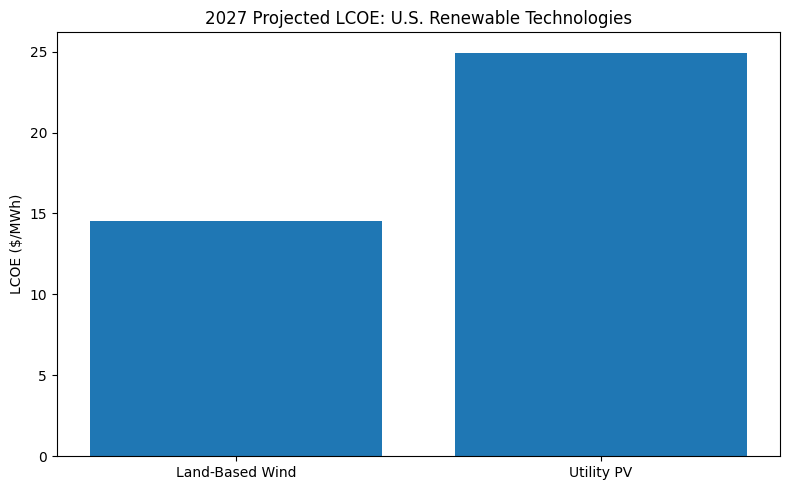

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    lcoe_table["Technology"],
    lcoe_table["LCOE ($/MWh)"]
)

plt.ylabel("LCOE ($/MWh)")
plt.title("2027 Projected LCOE: U.S. Renewable Technologies")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

### Key Insight

Under the selected NREL ATB 2024 assumptions, land-based wind has a lower
projected 2027 LCOE than utility-scale solar.

Wind has a higher estimated capital cost per kW than solar, but its higher
capacity factor results in greater electricity generation from the installed
capacity over time. This contributes to the lower LCOE.

This illustrates why capital cost alone is not sufficient for comparing
electricity generation technologies.

In [15]:
lcoe_table.index.name = None
lcoe_table

core_metric_parameter,Technology,CAPEX ($/kW),Fixed O&M ($/kW-year),LCOE ($/MWh),Capacity Factor (%)
0,Land-Based Wind,1504.64,30.46,14.53,46.52
1,Utility PV,1372.38,19.79,24.94,28.49


## 5. Sensitivity Analysis: Cost Recovery Period

The base case assumes a 30-year cost recovery period. To evaluate the impact
of this assumption, LCOE is compared across 20-year and 30-year cost recovery
periods while keeping the market case, scenario, projection year, technology,
and tax-credit case constant.

A shorter cost recovery period increases the annualized recovery of upfront
capital costs and can therefore increase LCOE.

In [16]:
sensitivity = df[
    (
        (df["technology_alias"] == "Utility PV") &
        (df["techdetail"] == "Class4")
    )
    |
    (
        (df["technology_alias"] == "Land-Based Wind") &
        (df["techdetail"] == "Class4")
    )
].copy()

sensitivity = sensitivity[
    (sensitivity["core_metric_case"] == "Market") &
    (sensitivity["scenario"] == "Moderate") &
    (sensitivity["core_metric_variable"] == 2027) &
    (sensitivity["tax_credit_case"] == "PTC") &
    (sensitivity["core_metric_parameter"] == "LCOE") &
    (sensitivity["crpyears"].isin([20, 30]))
].copy()

sensitivity[
    [
        "technology_alias",
        "techdetail",
        "crpyears",
        "core_metric_parameter",
        "value"
    ]
]

,technology_alias,techdetail,crpyears,core_metric_parameter,value
7743,Land-Based Wind,Class4,20,LCOE,16.16
8193,Land-Based Wind,Class4,30,LCOE,14.53
11854,Utility PV,Class4,20,LCOE,29.39
12298,Utility PV,Class4,30,LCOE,24.94


In [17]:
sensitivity_table = (
    sensitivity
    .pivot(
        index="technology_alias",
        columns="crpyears",
        values="value"
    )
    .reset_index()
)

sensitivity_table = sensitivity_table.rename(
    columns={
        "technology_alias": "Technology",
        20: "LCOE - 20 Years ($/MWh)",
        30: "LCOE - 30 Years ($/MWh)"
    }
)

sensitivity_table

crpyears,Technology,LCOE - 20 Years ($/MWh),LCOE - 30 Years ($/MWh)
0,Land-Based Wind,16.16,14.53
1,Utility PV,29.39,24.94


In [18]:
sensitivity_table.index.name = None

In [19]:
sensitivity_table["Change ($/MWh)"] = (
    sensitivity_table["LCOE - 20 Years ($/MWh)"]
    - sensitivity_table["LCOE - 30 Years ($/MWh)"]
)

sensitivity_table["Change (%)"] = (
    sensitivity_table["Change ($/MWh)"]
    / sensitivity_table["LCOE - 30 Years ($/MWh)"]
    * 100
).round(2)

sensitivity_table

crpyears,Technology,LCOE - 20 Years ($/MWh),LCOE - 30 Years ($/MWh),Change ($/MWh),Change (%)
0,Land-Based Wind,16.16,14.53,1.63,11.22
1,Utility PV,29.39,24.94,4.45,17.84


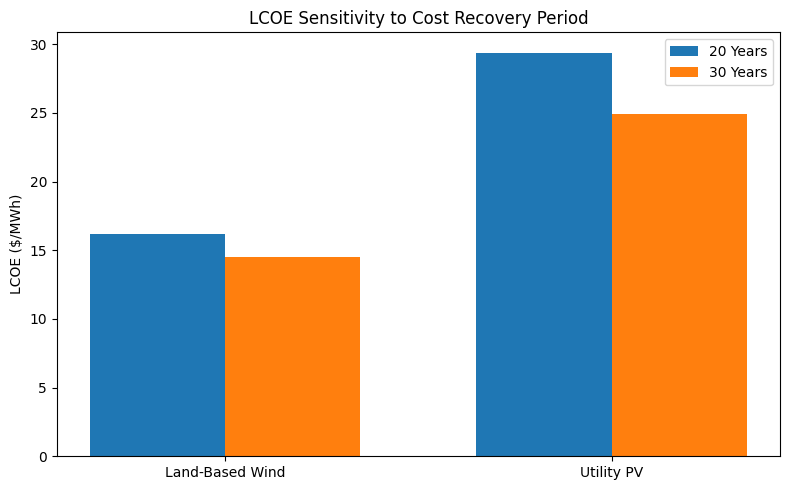

In [20]:
plt.figure(figsize=(8, 5))

x = np.arange(len(sensitivity_table))
width = 0.35

plt.bar(
    x - width/2,
    sensitivity_table["LCOE - 20 Years ($/MWh)"],
    width,
    label="20 Years"
)

plt.bar(
    x + width/2,
    sensitivity_table["LCOE - 30 Years ($/MWh)"],
    width,
    label="30 Years"
)

plt.xticks(
    x,
    sensitivity_table["Technology"]
)

plt.ylabel("LCOE ($/MWh)")
plt.title("LCOE Sensitivity to Cost Recovery Period")
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
lcoe_table.columns.name = None
sensitivity_table.columns.name = None

In [22]:
lcoe_table

,Technology,CAPEX ($/kW),Fixed O&M ($/kW-year),LCOE ($/MWh),Capacity Factor (%)
0,Land-Based Wind,1504.64,30.46,14.53,46.52
1,Utility PV,1372.38,19.79,24.94,28.49


In [23]:
sensitivity_table

,Technology,LCOE - 20 Years ($/MWh),LCOE - 30 Years ($/MWh),Change ($/MWh),Change (%)
0,Land-Based Wind,16.16,14.53,1.63,11.22
1,Utility PV,29.39,24.94,4.45,17.84


## 6. Key Findings

### 1. Wind has the lower projected LCOE

Under the selected NREL ATB 2024 assumptions, land-based wind has a projected
2027 LCOE of **$14.53/MWh**, compared with **$24.94/MWh** for utility-scale
solar PV.

Wind's LCOE is approximately **42% lower** than solar's in the selected
base case.

### 2. Capacity factor is an important driver

Land-based wind has a higher capital cost of approximately **$1,504.64/kW**
compared with **$1,372.38/kW** for utility-scale solar. However, wind has a
much higher capacity factor of **46.52%**, compared with **28.49%** for solar.

This demonstrates why comparing capital cost alone does not provide a complete
view of generation economics.

### 3. LCOE is sensitive to the cost recovery period

Reducing the cost recovery period from 30 years to 20 years increases LCOE
for both technologies.

- Wind increases from **$14.53/MWh to $16.16/MWh**, an increase of **11.22%**.
- Solar increases from **$24.94/MWh to $29.39/MWh**, an increase of **17.84%**.

Solar therefore shows greater sensitivity to the selected cost recovery
assumption in this analysis.

## 7. Limitations

This analysis evaluates generation cost using LCOE and should not be
interpreted as a complete measure of electricity-market competitiveness.

Key limitations include:

- LCOE does not capture the full market value of electricity generated at
  different times and locations.
- The analysis does not account for transmission constraints or grid
  interconnection costs.
- Wind and solar have different generation profiles and levels of
  dispatchability.
- The analysis uses a single NREL scenario and projection year rather than
  modeling multiple market conditions.
- The results depend on assumptions regarding capital costs, financing,
  operating costs, capacity factors, tax incentives, and cost recovery
  periods.
- Natural gas was not included in the direct LCOE comparison because the
  selected NREL ATB dataset does not provide directly comparable LCOE inputs
  for fossil technologies.

## 8. Conclusion

The analysis indicates that land-based wind has a lower projected 2027 LCOE
than utility-scale solar PV under the selected NREL ATB 2024 assumptions.

The analysis also shows that cost recovery assumptions materially affect
generation economics. Solar experienced a larger percentage increase in LCOE
when the cost recovery period was reduced from 30 to 20 years.

Overall, the results demonstrate that evaluating generation technologies
requires consideration of both capital costs and operating characteristics,
particularly capacity factor and financing assumptions. LCOE provides a useful
cost benchmark, but additional market and system-level factors are required
to evaluate the broader competitiveness of generation resources.